Coletando dados de 15m para BTC-USD...


[*********************100%***********************]  1 of 1 completed
~\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



=== AVISOS DE ALTA CONVICÇÃO ===
Período analisado     : 31.0 dias
Total de avisos       : 44  (~1.4 por dia)
Acertos               : 29/44
TAXA DE ACERTO        : 66%   (meta: >= 80%)
Config: LIMIAR=0.85  CONFIRMA=2  COOLDOWN=48  HORIZONTE=10


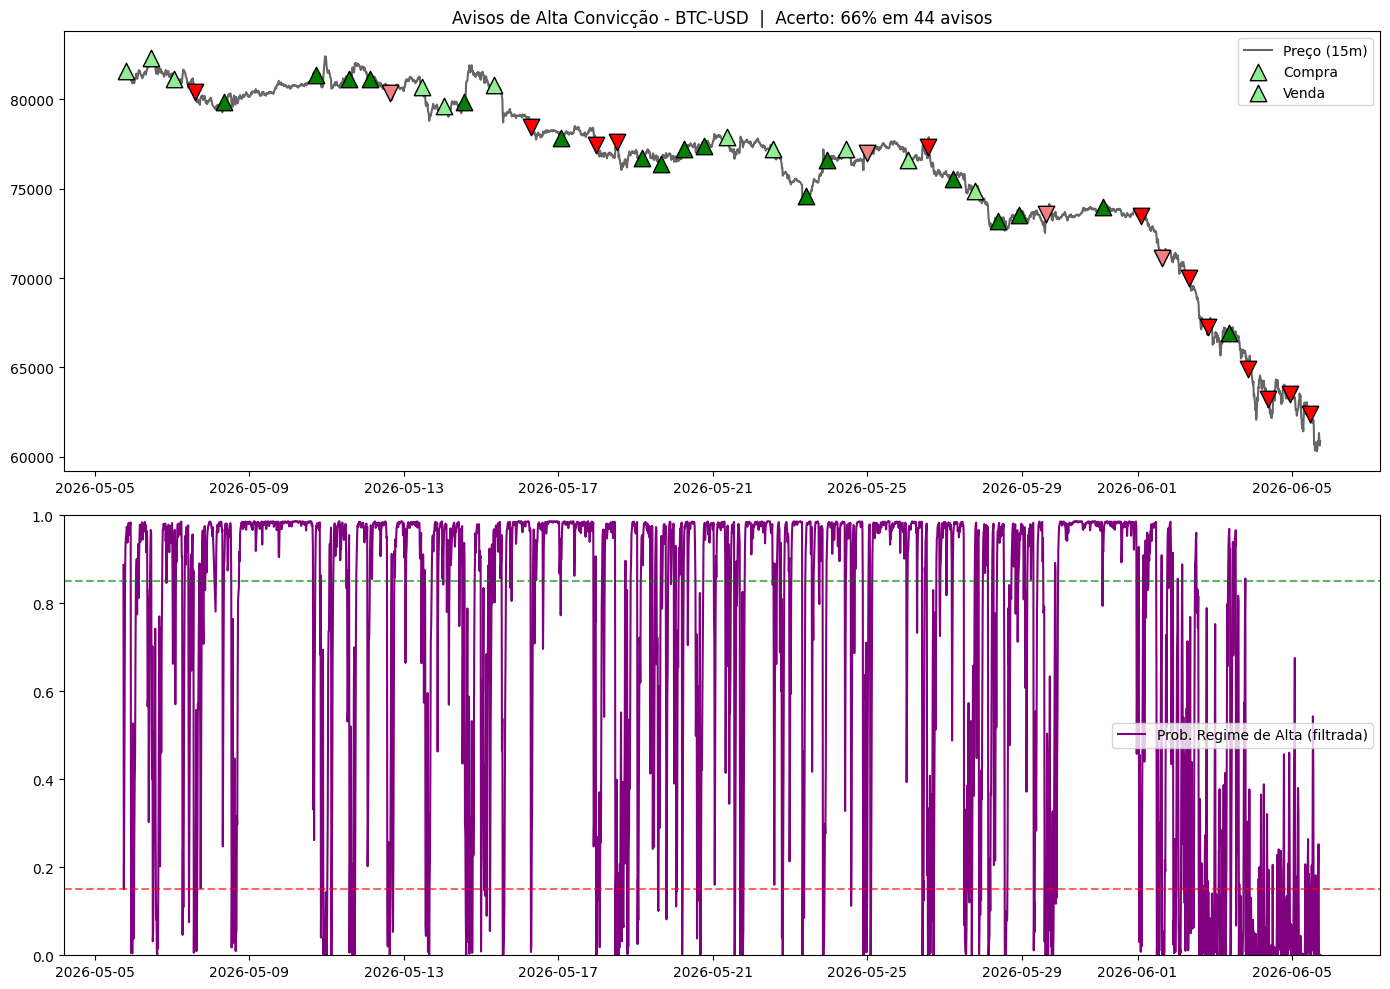

In [16]:
import yfinance as yf
import pandas as pd
import numpy as np
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURAÇÃO
# ============================================================
ticker    = 'BTC-USD'
intervalo = '15m'
periodo   = '1mo'   # 1 mês de histórico -> regimes estáveis e taxa de acerto confiável

# --- Controles de QUALIDADE do aviso (menos avisos, mais acerto) ---
LIMIAR    = 0.85   # confiança mínima do regime p/ considerar um aviso (85%)
CONFIRMA  = 2      # nº de velas seguidas no regime p/ confirmar (anti-ruído)
COOLDOWN  = 48     # mín. de velas entre avisos (24 x 15min = 6h)
HORIZONTE = 10      # velas à frente p/ checar se o aviso "se concretizou" (8 x 15min = 2h)

print(f"Coletando dados de {intervalo} para {ticker}...")

# ============================================================
# DADOS + MODELO DE MARKOV (2 regimes)
# ============================================================
data = yf.download(ticker, period=periodo, interval=intervalo)
if isinstance(data.columns, pd.MultiIndex):
    df = data['Close'].iloc[:, 0].to_frame(name='close')
else:
    df = data['Close'].to_frame(name='close')

df['returns'] = df['close'].pct_change()
df = df.dropna()

model = MarkovRegression(df['returns'], k_regimes=2,
                         switching_trend=True, switching_variance=True)
res = model.fit(disp=False)

# Probabilidade FILTRADA (sem look-ahead)
prob = res.filtered_marginal_probabilities
df['regime'] = prob.values.argmax(axis=1)
medias = df.groupby('regime')['returns'].mean()
regime_alta = int(medias.idxmax())
df['prob_alta'] = prob.iloc[:, regime_alta].values

# ============================================================
# AVISOS DE ALTA CONVICÇÃO
#   - exige CONFIRMA velas seguidas com prob > LIMIAR (compra) ou < 1-LIMIAR (venda)
#   - respeita COOLDOWN velas entre avisos
# ============================================================
acima  = df['prob_alta'] > LIMIAR
abaixo = df['prob_alta'] < (1 - LIMIAR)
conf_alta  = acima.rolling(CONFIRMA).sum()  == CONFIRMA
conf_baixa = abaixo.rolling(CONFIRMA).sum() == CONFIRMA

# evento = 1ª vela em que a confirmação passa a valer
ev_compra = conf_alta  & ~conf_alta.shift(1, fill_value=False)
ev_venda  = conf_baixa & ~conf_baixa.shift(1, fill_value=False)

df['sinal'] = 0
ultimo = -10**9
for i in range(len(df)):
    if i - ultimo < COOLDOWN:
        continue
    if ev_compra.iloc[i]:
        df.iloc[i, df.columns.get_loc('sinal')] = 1;  ultimo = i
    elif ev_venda.iloc[i]:
        df.iloc[i, df.columns.get_loc('sinal')] = -1; ultimo = i

# ============================================================
# CHECA SE CADA AVISO "SE CONCRETIZOU" (preço foi pro lado previsto em HORIZONTE velas)
# ============================================================
preco_futuro = df['close'].shift(-HORIZONTE)
df['acertou'] = np.nan
compra = df['sinal'] == 1
venda  = df['sinal'] == -1
df.loc[compra, 'acertou'] = (preco_futuro[compra] > df['close'][compra]).astype(float)
df.loc[venda,  'acertou'] = (preco_futuro[venda]  < df['close'][venda]).astype(float)

avisos = df[df['sinal'] != 0]
dias = (df.index[-1] - df.index[0]).total_seconds() / 86400
n_avisos = len(avisos)
acertos = int(avisos['acertou'].sum())
taxa = acertos / n_avisos if n_avisos else float('nan')

# ============================================================
# RELATÓRIO + GRÁFICO
# ============================================================
print("\n=== AVISOS DE ALTA CONVICÇÃO ===")
print(f"Período analisado     : {dias:.1f} dias")
print(f"Total de avisos       : {n_avisos}  (~{n_avisos/dias:.1f} por dia)")
print(f"Acertos               : {acertos}/{n_avisos}")
print(f"TAXA DE ACERTO        : {taxa:.0%}   (meta: >= 80%)")
print(f"Config: LIMIAR={LIMIAR}  CONFIRMA={CONFIRMA}  COOLDOWN={COOLDOWN}  HORIZONTE={HORIZONTE}")

plt.figure(figsize=(14, 10))
ax1 = plt.subplot(2, 1, 1)
ax1.plot(df['close'], color='black', alpha=0.6, label='Preço (15m)')
for _, r in avisos.iterrows():
    ok = r['acertou'] == 1
    if r['sinal'] == 1:
        ax1.scatter(r.name, r['close'], marker='^', s=140,
                    color='green' if ok else 'lightgreen',
                    edgecolors='black', zorder=5)
    else:
        ax1.scatter(r.name, r['close'], marker='v', s=140,
                    color='red' if ok else 'lightcoral',
                    edgecolors='black', zorder=5)
ax1.set_title(f'Avisos de Alta Convicção - {ticker}  |  Acerto: {taxa:.0%} em {n_avisos} avisos')
ax1.legend(['Preço (15m)', 'Compra', 'Venda'])

ax2 = plt.subplot(2, 1, 2, sharex=ax1)
ax2.plot(df['prob_alta'], color='purple', label='Prob. Regime de Alta (filtrada)')
ax2.axhline(LIMIAR, color='green', linestyle='--', alpha=0.6)
ax2.axhline(1 - LIMIAR, color='red', linestyle='--', alpha=0.6)
ax2.set_ylim(0, 1)
ax2.legend()

plt.tight_layout()
plt.show()

=== BACKTEST ===
Retorno da Estratégia : +10.45%
Retorno Buy & Hold    : -25.14%
Trocas de posição     : 18
Taxa de acerto (vela) : 51.01%  (1512/2964)
Sharpe (anualizado)   : 3.18


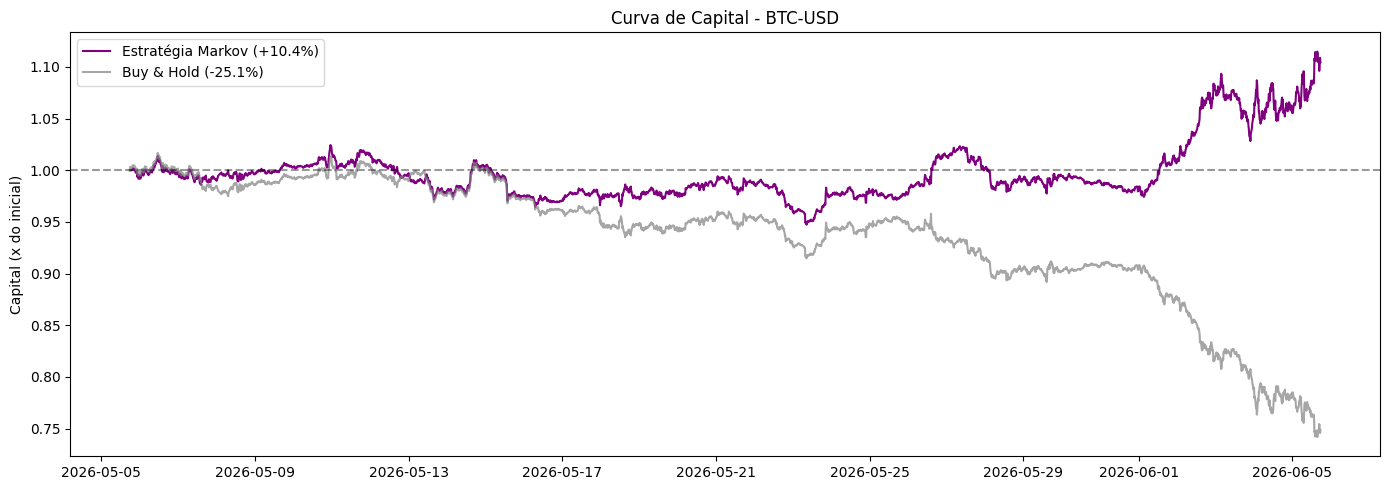

In [17]:
# ============================================================
# BACKTEST - mede objetivamente se o modelo "acerta"
# (roda DEPOIS da célula anterior; usa df, limiar)
# ============================================================

# 1. Posição contínua a partir dos sinais:
#    compra -> fica comprado (+1); venda -> fica vendido (-1); mantém até o próximo sinal.
df['position'] = np.nan
df.loc[df['sinal'] == 1, 'position'] = 1
df.loc[df['sinal'] == -1, 'position'] = -1
df['position'] = df['position'].ffill().fillna(0)

# 2. Retorno da estratégia SEM look-ahead:
#    a posição decidida no fim da vela só rende na vela seguinte -> shift(1).
df['ret_estrategia'] = df['position'].shift(1) * df['returns']

# 3. Curvas de capital (começa em 1.0 = 100%)
df['equity_estrategia'] = (1 + df['ret_estrategia']).cumprod()
df['equity_bh']        = (1 + df['returns']).cumprod()

# 4. Métricas
ret_estrat = df['equity_estrategia'].iloc[-1] - 1
ret_bh     = df['equity_bh'].iloc[-1] - 1
n_trocas   = int((df['position'].diff().fillna(0) != 0).sum())

mask = df['position'].shift(1) != 0                      # velas em que estávamos posicionados
acertos = int((df['ret_estrategia'][mask] > 0).sum())   # velas que deram lucro
total   = int(mask.sum())
taxa_acerto = acertos / total if total else float('nan')

# Sharpe anualizado (15min -> 96 velas/dia, ~365 dias cripto)
n_ano = 96 * 365
sharpe = (df['ret_estrategia'].mean() / df['ret_estrategia'].std() * np.sqrt(n_ano)
          if df['ret_estrategia'].std() else float('nan'))

print("=== BACKTEST ===")
print(f"Retorno da Estratégia : {ret_estrat:+.2%}")
print(f"Retorno Buy & Hold    : {ret_bh:+.2%}")
print(f"Trocas de posição     : {n_trocas}")
print(f"Taxa de acerto (vela) : {taxa_acerto:.2%}  ({acertos}/{total})")
print(f"Sharpe (anualizado)   : {sharpe:.2f}")

# 5. Gráfico das curvas de capital
plt.figure(figsize=(14, 5))
plt.plot(df['equity_estrategia'], label=f'Estratégia Markov ({ret_estrat:+.1%})', color='purple')
plt.plot(df['equity_bh'], label=f'Buy & Hold ({ret_bh:+.1%})', color='gray', alpha=0.7)
plt.axhline(1.0, color='black', linestyle='--', alpha=0.4)
plt.title(f'Curva de Capital - {ticker}')
plt.ylabel('Capital (x do inicial)')
plt.legend()
plt.tight_layout()
plt.show()